# Clasificador de ladridos según el tamaño del animal. - Base de datos

### Pruebas estadisticas

En el siguiente bloque nos enfocamos en adjuntar la información entregada desde el CSV, formamos uan tabla inicial que contenga la información para realizar nuestra prueba estadistica de chi-cuadrado, para comprobar sí existe una dependencia entre raza y sexo del perro. Dado que la dependencia sería el sesgo más grande para nuestra experimentación optamos por no verificar normalidad en nuestros datos.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import librosa
from scipy import stats

df = pd.read_csv(f'metadataDogsSpeakTDS.csv')

TAMANO_RAZA = {
    'chihuahua':       'pequeño',
    'shiba inu':       'pequeño',
    'pitbull':         'grande',
    'husky':           'grande',
    'german shepherd': 'grande',
}

df['size'] = df['breed'].map(TAMANO_RAZA)
print(df['size'].isna().sum(), 'audios sin tamaño')

perros = df.drop_duplicates('dog_id')[['dog_id', 'breed', 'sex', 'size']]

print(len(perros), 'perros')
print(perros['breed'].value_counts())
print(df.groupby('dog_id').size().value_counts().sort_index())   # cuántos perros tienen 1, 2, 3... audios

0 audios sin tamaño
122 perros
breed
german shepherd    31
husky              28
pitbull            27
shiba inu          24
chihuahua          12
Name: count, dtype: int64
2    110
4     12
Name: count, dtype: int64


In [46]:
import os
import glob
import wave

ALPHA = 0.05

def evaluar_hipotesis(nombre, h0, h1, estadistico_txt, p_valor, decision_si_rechaza, decision_no_rechaza):
    print(f"\n{'='*70}")
    print(f"PRUEBA: {nombre}")
    print(f"  H0: {h0}")
    print(f"  H1: {h1}")
    print(f"  Nivel de significancia: alpha = {ALPHA}")
    print(f"  Resultado: {estadistico_txt}, p-valor = {p_valor:.6f}")
    if p_valor < ALPHA:
        print(f"  Decisión estadística: Como p ({p_valor:.6f}) < alpha ({ALPHA}), SE RECHAZA H0.")
        print(f"  Decisión metodológica: {decision_si_rechaza}")
    else:
        print(f"  Decisión estadística: Como p ({p_valor:.6f}) >= alpha ({ALPHA}), NO SE RECHAZA H0.")
        print(f"  Decisión metodológica: {decision_no_rechaza}")

# RAZA A SEXO
tabla_rs = pd.crosstab(perros['breed'], perros['sex'])
chi2_rs, p_rs, gl_rs, _ = stats.chi2_contingency(tabla_rs)
evaluar_hipotesis(
    nombre="Independencia entre Raza y Sexo (Chi-cuadrado)",
    h0="La raza y el sexo de los perros son independientes.",
    h1="Existe dependencia entre la raza y el sexo de los perros.",
    estadistico_txt=f"Chi2 = {chi2_rs:.4f} (gl = {gl_rs})",
    p_valor=p_rs,
    decision_si_rechaza="Verificar si esta dependencia de sexo se mantiene al agrupar por tamaño (Prueba 2).",
    decision_no_rechaza="El sexo se distribuye homogéneamente entre todas las razas."
)

# TAMAÑO A SEXO
tabla_ts = pd.crosstab(perros['size'], perros['sex'])
chi2_ts, p_ts, gl_ts, _ = stats.chi2_contingency(tabla_ts, correction=False)
evaluar_hipotesis(
    nombre="Independencia entre Tamaño y Sexo (Chi-cuadrado)",
    h0="El tamaño del perro (grande/pequeño) y su sexo son independientes.",
    h1="Existe dependencia entre el tamaño del perro y su sexo.",
    estadistico_txt=f"Chi2 = {chi2_ts:.4f} (gl = {gl_ts})",
    p_valor=p_ts,
    decision_si_rechaza="Controlar el efecto del sexo al construir los vectores prototipo.",
    decision_no_rechaza="El sexo no es variable de confusión para clasificar por tamaño; no requiere separación por sexo."
)

# BALANCE DE PERROS POR TAMAÑO
conteo_tam = perros['size'].value_counts()
chi2_bal, p_bal = stats.chisquare(conteo_tam)
evaluar_hipotesis(
    nombre="Balance de individuos por Tamaño (Chi-cuadrado de bondad de ajuste)",
    h0="Hay igual proporción de perros grandes y pequeños (50% y 50%).",
    h1="Existe desbalance en la proporción de perros grandes y pequeños.",
    estadistico_txt=f"Chi2 = {chi2_bal:.4f} (gl = 1)",
    p_valor=p_bal,
    decision_si_rechaza="Calcular prototipos promediando primero por perro y luego por raza (sin mezclar todos los audios directos).",
    decision_no_rechaza="Se pueden promediar directamente todos los audios de cada clase."
)

# DURACIÓN DE LADRIDOS (GRANDES VS. PEQUEÑOS)
archivos_wav = glob.glob('DogSpeak_Seleccion/**/*.wav', recursive=True)
mapa_rutas = {os.path.basename(ruta): ruta for ruta in archivos_wav}

duraciones, fs_list = [], []
for fname in df['filename']:
    with wave.open(mapa_rutas[fname], 'rb') as wf:
        fs = wf.getframerate()
        fs_list.append(fs)
        duraciones.append(wf.getnframes() / float(fs))

df['fs'] = fs_list
df['duracion_s'] = duraciones

print(f"\nFrecuencias de muestreo encontradas (Hz): {df['fs'].value_counts().to_dict()}")
print(df.groupby('size')['duracion_s'].describe().round(4))

dur_g = df[df['size'] == 'grande']['duracion_s']
dur_p = df[df['size'] == 'pequeño']['duracion_s']

# Paso previo: Normalidad (Shapiro-Wilk)
_, p_norm_g = stats.shapiro(dur_g)
_, p_norm_p = stats.shapiro(dur_p)
print(f"\nNormalidad (Shapiro-Wilk): p_grande = {p_norm_g:.4e}, p_pequeño = {p_norm_p:.4e}")

if p_norm_g >= ALPHA and p_norm_p >= ALPHA:
    stat_dur, p_dur = stats.ttest_ind(dur_g, dur_p)
    metodo = f"t-Student = {stat_dur:.4f}"
else:
    stat_dur, p_dur = stats.mannwhitneyu(dur_g, dur_p)
    metodo = f"Mann-Whitney U = {stat_dur:.1f}"

evaluar_hipotesis(
    nombre="Comparación de duración de ladridos entre Grandes y Pequeños",
    h0="La duración de los ladridos es igual en perros grandes y pequeños.",
    h1="La duración de los ladridos difiere entre perros grandes y pequeños.",
    estadistico_txt=metodo,
    p_valor=p_dur,
    decision_si_rechaza="La duración aporta información discriminativa; elegir ventana corta según el percentil mínimo.",
    decision_no_rechaza="La duración no discrimina tamaño; enfocar las características en el contenido espectral (bancos de filtros)."
)


PRUEBA: Independencia entre Raza y Sexo (Chi-cuadrado)
  H0: La raza y el sexo de los perros son independientes.
  H1: Existe dependencia entre la raza y el sexo de los perros.
  Nivel de significancia: alpha = 0.05
  Resultado: Chi2 = 20.6581 (gl = 4), p-valor = 0.000370
  Decisión estadística: Como p (0.000370) < alpha (0.05), SE RECHAZA H0.
  Decisión metodológica: Verificar si esta dependencia de sexo se mantiene al agrupar por tamaño (Prueba 2).

PRUEBA: Independencia entre Tamaño y Sexo (Chi-cuadrado)
  H0: El tamaño del perro (grande/pequeño) y su sexo son independientes.
  H1: Existe dependencia entre el tamaño del perro y su sexo.
  Nivel de significancia: alpha = 0.05
  Resultado: Chi2 = 0.0051 (gl = 1), p-valor = 0.942803
  Decisión estadística: Como p (0.942803) >= alpha (0.05), NO SE RECHAZA H0.
  Decisión metodológica: El sexo no es variable de confusión para clasificar por tamaño; no requiere separación por sexo.

PRUEBA: Balance de individuos por Tamaño (Chi-cuadrado d

### Extracción de caracteristicas

In [47]:
from scipy.fft import dct

FS_OBJETIVO = 16000
WIN_LEN = int(FS_OBJETIVO * 0.025)   # 25 ms -> 400 muestras
HOP_LEN = int(WIN_LEN * 0.50)        # 50% solape -> 200 muestras

def extraer_mfcc_audio(ruta_audio):
    # Preprocesamiento: cargar mono, remuestrear a 16 kHz y normalizar amplitud
    y, _ = librosa.load(ruta_audio, sr=FS_OBJETIVO, mono=True)
    if np.max(np.abs(y)) > 0:
        y = y / np.max(np.abs(y))

    # Window + DFT (potencia) + Banco de filtros Mel (librosa)
    mel_potencia = librosa.feature.melspectrogram(
        y=y,
        sr=FS_OBJETIVO,
        n_fft=512,
        win_length=WIN_LEN,
        hop_length=HOP_LEN,
        window='hamming',
        n_mels=40,
        fmin=50.0,
        fmax=8000.0,
        power=2.0
    )

    # Conversión a dB y DCT -> 20 coeficientes MFCC
    mel_db = librosa.power_to_db(mel_potencia, ref=np.max) # POWER TO DB = potencia a escala de decibeles
    mfccs = dct(mel_db, type=2, axis=0, norm='ortho')[:20, :] # Conversión de la representación Mel a MFCC mediante DCT (Discrete Cosine Transform)

    # Resumen temporal: media y desviación estándar de cada coeficiente (40 features)
    return np.concatenate([np.mean(mfccs, axis=1), np.std(mfccs, axis=1)])

# Extraer matriz de características de DogsSpeakTDS (268 audios x 40 características)
X_tds = np.array([extraer_mfcc_audio(mapa_rutas[fname]) for fname in df['filename']])
print("Shape de X_tds:", X_tds.shape)

Shape de X_tds: (268, 40)


### Análisis de similitud

Vector de ambas categorias basada desde la DCT y los coeficientes cepstrales.

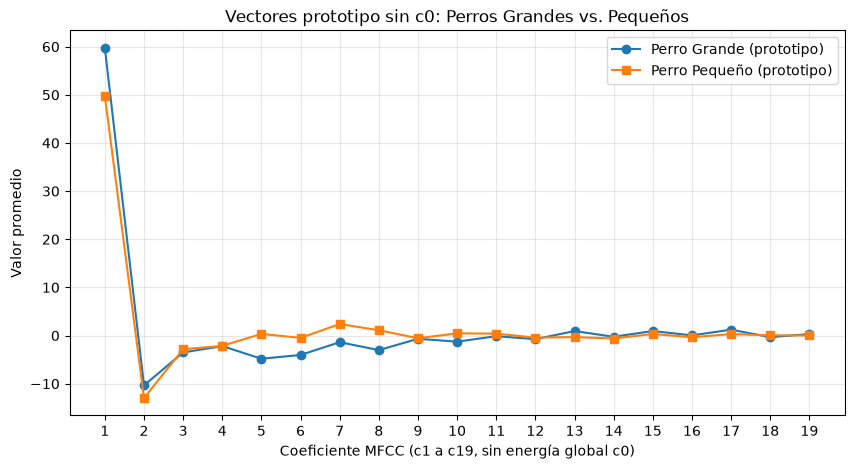

Nueva distancia coseno media (Grandes) : 0.1440
Nueva distancia coseno media (Pequeños): 0.1647


In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

# Índices de características SIN c0 (eliminamos el 0 de las medias y el 20 de las std)
idx_sin_c0 = [i for i in range(40) if i not in (0, 20)]

# Gráfica haciendo zoom en los coeficientes MFCC 1 al 19 (sin c0)
plt.figure(figsize=(10, 5))
plt.plot(range(1, 20), vector_promedio_tamano['grande'][1:20], marker='o', label='Perro Grande (prototipo)')
plt.plot(range(1, 20), vector_promedio_tamano['pequeño'][1:20], marker='s', label='Perro Pequeño (prototipo)')

plt.xlabel("Coeficiente MFCC (c1 a c19, sin energía global c0)")
plt.ylabel("Valor promedio")
plt.title("Vectores prototipo sin c0: Perros Grandes vs. Pequeños")
plt.xticks(range(1, 20))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Al calcular distancia coseno, comparas usando idx_sin_c0
vec_g_sin_c0 = vector_promedio_tamano['grande'][idx_sin_c0]
vec_p_sin_c0 = vector_promedio_tamano['pequeño'][idx_sin_c0]

dist_g_nueva = np.array([cosine(x[idx_sin_c0], vec_g_sin_c0) for x in X_tds[df['size'] == 'grande']])
dist_p_nueva = np.array([cosine(x[idx_sin_c0], vec_p_sin_c0) for x in X_tds[df['size'] == 'pequeño']])

print(f"Nueva distancia coseno media (Grandes) : {dist_g_nueva.mean():.4f}")
print(f"Nueva distancia coseno media (Pequeños): {dist_p_nueva.mean():.4f}")

Pruebas estadisticas mostrando las concentraciones y mostrando a su vez que tan concentradas se encuentran las representaciones de cada categoría alrededor de su respectivo vector de referencia.

=== CONCENTRACIÓN ALREDEDOR DEL PROTOTIPO (DISTANCIA COSENO SIN c0) ===
Grande  (n=172) -> Media: 0.1440 | Std: 0.1336 | Mediana: 0.0894 | IQR: 0.1214
Pequeño (n= 96) -> Media: 0.1647 | Std: 0.1145 | Mediana: 0.1241 | IQR: 0.1157


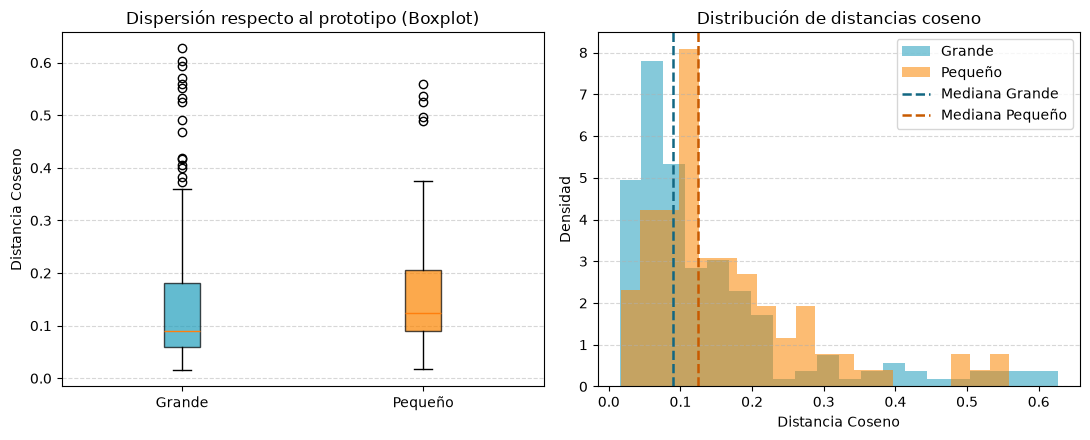


Normalidad (Shapiro-Wilk): p_grande = 1.3825e-15, p_pequeño = 1.1784e-08

PRUEBA: Comparación de concentración alrededor del prototipo (Grandes vs. Pequeños)
  H0: La concentración (distancia coseno al prototipo) es igual en grandes y pequeños.
  H1: Existe diferencia en la concentración entre perros grandes y pequeños.
  Nivel de significancia: alpha = 0.05
  Resultado: Mann-Whitney U = 6474.0, p-valor = 0.003409
  Decisión estadística: Como p (0.003409) < alpha (0.05), SE RECHAZA H0.
  Interpretación: Hay diferencia en la concentración. El grupo más concentrado (menor mediana de distancia) es: Grande.

PRUEBA: Chi-cuadrado de independencia (tamaño vs. cercanía al prototipo)
  H0: La proporción de audios cercanos al prototipo es igual en grandes y pequeños.
  H1: La proporción de audios cercanos al prototipo es distinta.
  Umbral de cercanía (mediana global de distancias): 0.1096
         Cerca  Lejos
Grande      97     75
Pequeño     37     59
Grande     0.564
Pequeño    0.385
  chi

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import cosine

ALPHA = 0.05

# 1. Índices de la DCT sin c0 (quitamos el índice 0 de medias y el 20 de desviaciones estándar)
idx_sin_c0 = [i for i in range(40) if i not in (0, 20)]

# 2. Prototipos de referencia de cada categoría (38 características)
proto_grande  = vector_promedio_tamano['grande'][idx_sin_c0]
proto_pequeno = vector_promedio_tamano['pequeño'][idx_sin_c0]

# Separar audios de DogsSpeakTDS por tamaño y calcular distancia coseno a su prototipo
X_grande  = X_tds[df['size'] == 'grande'][:, idx_sin_c0]
X_pequeno = X_tds[df['size'] == 'pequeño'][:, idx_sin_c0]

dist_grande  = np.array([cosine(x, proto_grande) for x in X_grande])
dist_pequeno = np.array([cosine(x, proto_pequeno) for x in X_pequeno])

# 3. Resumen estadístico descriptivo
print("=== CONCENTRACIÓN ALREDEDOR DEL PROTOTIPO (DISTANCIA COSENO SIN c0) ===")
for nombre, d in [('Grande ', dist_grande), ('Pequeño', dist_pequeno)]:
    iqr = np.percentile(d, 75) - np.percentile(d, 25)
    print(f"{nombre} (n={len(d):3d}) -> Media: {d.mean():.4f} | Std: {d.std():.4f} | "
          f"Mediana: {np.median(d):.4f} | IQR: {iqr:.4f}")

# 4. Gráficos comparativos de distribución (Boxplot + Histograma de densidad)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

bp = axes[0].boxplot([dist_grande, dist_pequeno],
                     tick_labels=['Grande', 'Pequeño'], patch_artist=True)
for patch, color in zip(bp['boxes'], ['#219EBC', '#FB8500']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0].set_title('Dispersión respecto al prototipo (Boxplot)')
axes[0].set_ylabel('Distancia Coseno')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].hist(dist_grande, bins=20, density=True, alpha=0.55, color='#219EBC', label='Grande')
axes[1].hist(dist_pequeno, bins=20, density=True, alpha=0.55, color='#FB8500', label='Pequeño')
axes[1].axvline(np.median(dist_grande), color='#126782', linestyle='--', lw=1.8, label='Mediana Grande')
axes[1].axvline(np.median(dist_pequeno), color='#C85A00', linestyle='--', lw=1.8, label='Mediana Pequeño')
axes[1].set_title('Distribución de distancias coseno')
axes[1].set_xlabel('Distancia Coseno')
axes[1].set_ylabel('Densidad')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 5. Contraste de hipótesis sobre concentración (formato del curso)
_, p_norm_g = stats.shapiro(dist_grande)
_, p_norm_p = stats.shapiro(dist_pequeno)
print(f"\nNormalidad (Shapiro-Wilk): p_grande = {p_norm_g:.4e}, p_pequeño = {p_norm_p:.4e}")

if p_norm_g >= ALPHA and p_norm_p >= ALPHA:
    stat, p_val = stats.ttest_ind(dist_grande, dist_pequeno, equal_var=False)   # Welch
    nombre_stat = f"t de Welch = {stat:.4f}"
else:
    stat, p_val = stats.mannwhitneyu(dist_grande, dist_pequeno)
    nombre_stat = f"Mann-Whitney U = {stat:.1f}"

print(f"\n{'='*70}")
print("PRUEBA: Comparación de concentración alrededor del prototipo (Grandes vs. Pequeños)")
print("  H0: La concentración (distancia coseno al prototipo) es igual en grandes y pequeños.")
print("  H1: Existe diferencia en la concentración entre perros grandes y pequeños.")
print(f"  Nivel de significancia: alpha = {ALPHA}")
print(f"  Resultado: {nombre_stat}, p-valor = {p_val:.6f}")

if p_val < ALPHA:
    mas_conc = 'Grande' if np.median(dist_grande) < np.median(dist_pequeno) else 'Pequeño'
    print(f"  Decisión estadística: Como p ({p_val:.6f}) < alpha ({ALPHA}), SE RECHAZA H0.")
    print(f"  Interpretación: Hay diferencia en la concentración. El grupo más concentrado "
          f"(menor mediana de distancia) es: {mas_conc}.")
else:
    print(f"  Decisión estadística: Como p ({p_val:.6f}) >= alpha ({ALPHA}), NO SE RECHAZA H0.")
    print("  Interpretación: Ambas categorías tienen una dispersión equivalente alrededor de su prototipo.")

# 6. Chi-cuadrado: proporción de audios "cercanos" al prototipo en cada categoría
umbral = np.median(np.concatenate([dist_grande, dist_pequeno]))   # umbral fijo: mediana global

tabla_conc = pd.DataFrame(
    [[(dist_grande  <= umbral).sum(), (dist_grande  > umbral).sum()],
     [(dist_pequeno <= umbral).sum(), (dist_pequeno > umbral).sum()]],
    index=['Grande', 'Pequeño'], columns=['Cerca', 'Lejos'])

chi2, p_chi, gl, esp = stats.chi2_contingency(tabla_conc)

print(f"\n{'='*70}")
print("PRUEBA: Chi-cuadrado de independencia (tamaño vs. cercanía al prototipo)")
print("  H0: La proporción de audios cercanos al prototipo es igual en grandes y pequeños.")
print("  H1: La proporción de audios cercanos al prototipo es distinta.")
print(f"  Umbral de cercanía (mediana global de distancias): {umbral:.4f}")
print(tabla_conc)
print((tabla_conc['Cerca'] / tabla_conc.sum(axis=1)).round(3).to_string())
print(f"  chi2 = {chi2:.3f}, gl = {gl}, p-valor = {p_chi:.6f}  (esperado mínimo = {esp.min():.1f})")

if p_chi < ALPHA:
    print(f"  Decisión estadística: Como p ({p_chi:.6f}) < alpha ({ALPHA}), SE RECHAZA H0.")
else:
    print(f"  Decisión estadística: Como p ({p_chi:.6f}) >= alpha ({ALPHA}), NO SE RECHAZA H0.")

# Desde mis propios perros

In [55]:
import glob, os
import pandas as pd

BASE_MIS = 'MisPerros'          # ajusta
extensiones = ('.wav', '.ogg', '.m4a', '.mp4', '.mp3')

rutas = sorted(r for r in glob.glob(f'{BASE_MIS}/**/*', recursive=True)
               if os.path.isfile(r) and r.lower().endswith(extensiones))

mis = pd.DataFrame({'ruta': rutas})
mis['dog_id'] = mis['ruta'].apply(lambda r: os.path.basename(os.path.dirname(r)))   # carpeta que contiene el audio

print(len(mis), 'audios,', mis['dog_id'].nunique(), 'perros')
print(mis.groupby('dog_id').size())

TAMANO_MIS = {
    'Alaska': 'grande',
    'Aslan': 'grande',
    'Rocco': 'grande',
    # ... los 10
}

mis['size'] = mis['dog_id'].map(TAMANO_MIS)
print(mis['size'].isna().sum(), 'audios sin tamaño')                # debe ser 0
print(mis.drop_duplicates('dog_id')['size'].value_counts())          # 5 y 5

9 audios, 3 perros
dog_id
Alaska    3
Aslan     3
Rocco     3
dtype: int64
0 audios sin tamaño
size
grande    3
Name: count, dtype: int64


In [52]:
X_mis = np.array([extraer_mfcc_audio(r) for r in mis['ruta']])
print(X_mis.shape)          # (30, 40)

(9, 40)


In [53]:
Xm = X_mis[:, idx_sin_c0]

mis['d_grande']  = [cosine(x, proto_grande)  for x in Xm]
mis['d_pequeno'] = [cosine(x, proto_pequeno) for x in Xm]
mis['pred_audio'] = np.where(mis['d_grande'] < mis['d_pequeno'], 'grande', 'pequeño')

print(mis[['dog_id', 'size', 'd_grande', 'd_pequeno', 'pred_audio']].round(4))
print('Exactitud por audio:', round((mis['pred_audio'] == mis['size']).mean(), 3))

KeyError: "['size'] not in index"

In [ ]:
por_perro = mis.groupby('dog_id').agg(size=('size', 'first'),
                                      d_grande=('d_grande', 'mean'),
                                      d_pequeno=('d_pequeno', 'mean'))
por_perro['pred'] = np.where(por_perro['d_grande'] < por_perro['d_pequeno'], 'grande', 'pequeño')

# Alternativa para comparar: voto mayoritario de los 3 audios
por_perro['pred_voto'] = mis.groupby('dog_id')['pred_audio'].agg(lambda s: s.value_counts().idxmax())

print(por_perro.round(4))
print('Exactitud por perro (distancia media):', (por_perro['pred'] == por_perro['size']).mean())
print('Exactitud por perro (voto mayoritario):', (por_perro['pred_voto'] == por_perro['size']).mean())

In [ ]:
orden = ['pequeño', 'grande']
cm = pd.crosstab(por_perro['size'], por_perro['pred']).reindex(index=orden, columns=orden, fill_value=0)
print(cm)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm.values, cmap='Blues')
ax.set_xticks([0, 1]); ax.set_xticklabels(orden)
ax.set_yticks([0, 1]); ax.set_yticklabels(orden)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm.values[i, j], ha='center', va='center', fontsize=14)
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title('Matriz de confusión (10 perros)')
plt.tight_layout(); plt.show()